<center><font size="4"><b>Technologia Mowy 2026</b></font></center>
<br />
<center><font size="6"><b><u>Lab 1: Colab & Jupyter & Python</u></b></font></center>
<br />
<br />

<center><b>Notebook version:</b> 0.3 (14.10.2026)</center>
<center>Copyright Marcin Witkowski, AGH, 2026</center>


# Audio
W ramach laboaratorium przetwarzanie sygnału audio będzie występowało dość częśto. Poniższy fragment demonstruje możliwości notatnika Colab w tym zakresie.

W poniższym fragmencie kodu, korzystając z funkcji w pakiecie [NumPy](https://numpy.org/doc/stable/) tworzymy sygnał o długości 5 sekund zawierający 2 składowe oraz znormalizujmy go. Zwróć uwagę, że w `numpy` operatory `/` oraz `*` domyślnie oznaczają iloraz i iloczyn po współrzędnych (*element-wise*, odpowiadające Matlabowemu `./` i `.*`). W celu wykonania klasycznego mnożenia macierzy należy skorzystać z funkcji `np.dot()`.

In [ ]:
import numpy as np

fs = 16000
t = np.linspace(0,5,fs*5)
x = np.sin(2*np.pi*164.81*t) + np.sin(2*np.pi*196*t) + np.sin(2*np.pi*246.94*t)
x = 0.8 * x / np.max(x)

Sprawdźmy, czy dane zawarte w wektorze `x` faktycznie zawierają zdefiniowany sygnał. W tym celu po pierwsze wyświetlimy zawartość wektora oraz korzystając z pakietu `matplotlib` wyświetlimy jego fragment.

[ 0.          0.06364657  0.12685636 ... -0.22515435 -0.19935628
 -0.17141295]
80000


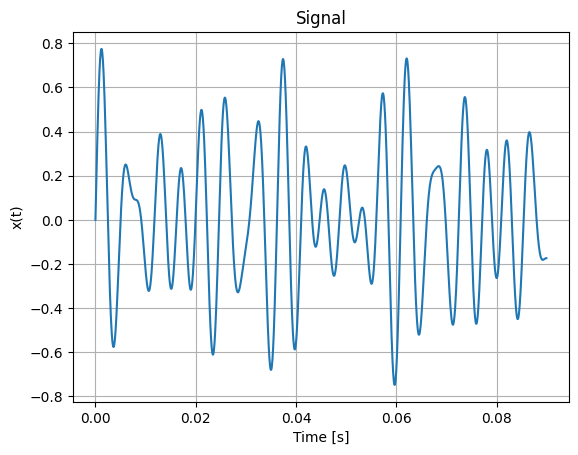

In [ ]:
print(x)
print(len(x))

import matplotlib.pyplot as plt

# Plot the points using matplotlib
t_stop = int(0.09 * fs)
sig_range = np.array(range(0,t_stop))
plt.plot(t[sig_range], x[sig_range])
plt.xlabel('Time [s]')
plt.ylabel('x(t)')
plt.title('Signal')
plt.grid()

Spośród pakietów umożliwijających wczytywanie i zapis danych audio w przestrzeni roboczej Pythona `scipy.io.wavfile` umożliwia załadowanie danych bezpośrednio do tablicy `numpy.array`. W tej postaci można łatwo posługiwać się danymi w celu wyświetlania, analizy czy przetwarzania. Poniższy fragment kodu importuje funkcję `read()` i `write()` o interfejsach zbliżonych do funkcji `audioread()` i `audiowrite()` w Matlabie.

In [ ]:
from scipy.io.wavfile import read
from scipy.io.wavfile import write

write('signal.wav', rate=fs, data=x)

Korzystając z `read()` oraz normy zaimplementowanej w `numpy.linalg` sprawdźmy, czy wczytany sygnał faktycznie będzie tym samym sygnałem. Sygnał został zapisany w domyślnym katalogu maszyny wirtualnej utworzonej dla tej sesji. Zwróć uwagę, że argumenty wyjściowe `scipy.io.wavfile.read()` są w odwrotnej kolejności niż w funkcji `audioread()` w Matlabie.


In [ ]:
fs2, y = read('signal.wav')

print("||x - y|| = ", np.linalg.norm(x-y))

||x - y|| =  0.0


W ramach notatnika, możemy również bezpośrednio odsłuchać jak brzmi sygnał, bez konieczności uruchamiania dodatkowego środowiska.

In [ ]:
from IPython.display import Audio

# Generate a player for mono sound
Audio(x,rate=fs,autoplay=False)

Pracując w Google Colaboratory warto zapoznać się ze [skrótami klawiszowymi bardzo przyspieszającymi pracę](https://amitness.com/2020/06/google-colaboratory-tips/#4-jupyter-notebook-keyboard-shortcuts)!



---



# Colab notebook i Google Drive





## Montowanie dysku Google
Podczas uruchamiania notatnika w Google Colaboratory tworzona jest osobna sesja, w ramach której uruchamiana jest wirtualna maszyna indywidualna dla każdego notatnika (każdego użytkownika). Wirtualna maszyna posiada własny system plików (oparty o system Unix) osobny dla każego notatnika. Oznacza to, że domyślnie notatnik "widzi" tylko pliki w "swojej" maszynie.

Dlatego aby uzyskać dostęp do plików z dysku Google należy zamontować dysk zalogowanego użytkownika. W tym celu należy wywołać poniższy kod, który powinien zakończyć się autentykacją Google.

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive/', force_remount=True)

Mounted at /content/gdrive/


## Zmiana katalogu roboczego w notatniku

Aby zmienić katalog roboczy w notatniku przejdź do odpowiedniego katalogu na swoim dysku Google. W wersji początkowej przechodzimy do korzenia struktury katalogów w Twoim dysku, więc możesz zmienić ścieżkę na dowolny podkatalog.

In [ ]:
import os
root = '/content/gdrive/MyDrive/colab/tm2026/'  # Wpisz tu ścieżkę do katalogu roboczego na dysku google
os.chdir(root)

!ls  # W celu użycia komend ze środowiska unix używaj znaku wykrzyknika (!) lub procentu (%) przed komendą
%ls

adfasdfdasfaw.gsheet
adfasdfdasfaw.gsheet


## Katalogi współdzielone

Zauważ, że obecnie notatnik posiada dostęp do wszystkich plików przechowywanych w dysku ale **nie do plików/katalogów współdzielonych**.

Pracując w grupie studenckiej na tych samych plikach wygodnie jest posiadać wspólną przestrzeń, tak by każda osoba w grupie miała dostęp do tych samych plików.

Dlatego najwygodniej by **dla wszystkich studentów w podgrupie ścieżka do współdzielonego katalogu była taka sama**. W tym celu osoba tworząca katalog (lider) może utworzyć go w docelowym miejscu. Pozostali członkowie grupy powinni utworzyć skrót do współdzielonego katalogu w tożsamej ścieżce na swoim dysku. W sekcji `Udostępnione dla mnie` w dysku Google należy kliknąć na katalog prawym przyciskiem myszy i wybrać `Organizuj > Dodaj skrót`, jak na rysunku poniżej.



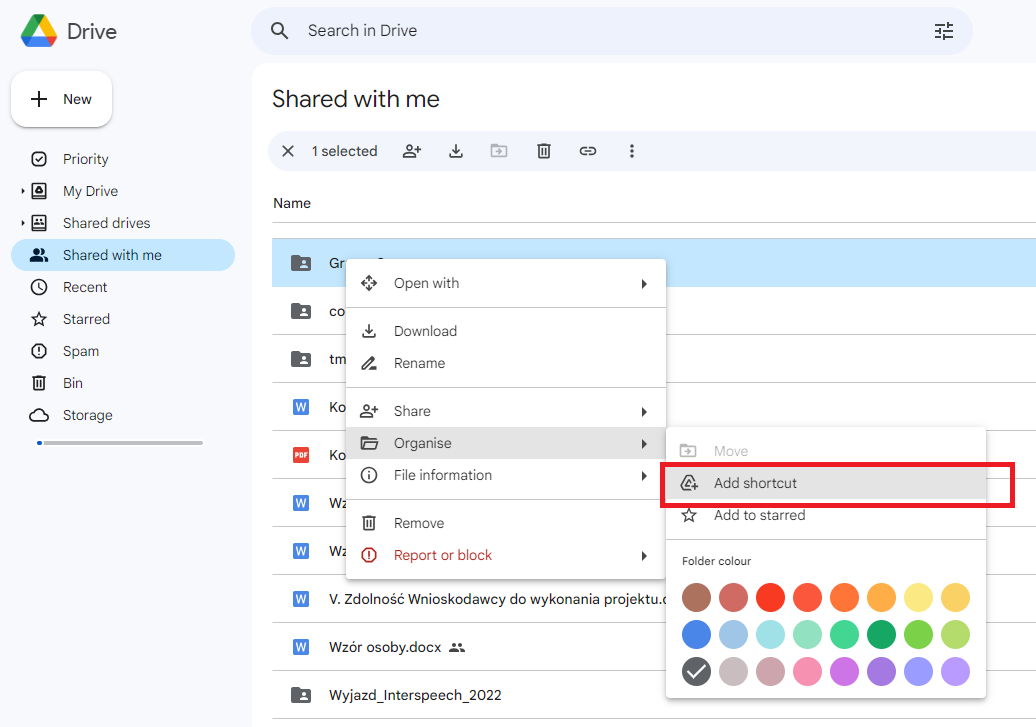



## Algorytm
Sugerowany algorytm by przeprowadzić tę operację:

1.   Wybierz lidera grupy, który na swoim dysku Google tworzy katalogi  `colab/tm2026/GrupaX`, gdzie `X` odpowiada numerowi grupy.
2.   Lider udostępnia katalog `colab/tm2026/GrupaX` pozostałym członkom zespołu ORAZ prowadzącemu (witkow@agh.edu.pl).
3. Pozostali członkowie dodają skrót do katalogu tak aby również ścieżka do katalogu wskazywała `colab/tm2026/GrupaX`.
4. Lider dodaje do katalogu kopię tego notatnika.

Wykonanie algorytmu spowoduje, że każdy z użytkowników otwierając ten notatnik ze wspóldzielonego katalogu będzie miał dostęp do tych samych plików. Zwróć uwagę, że jeśli dokonasz zapisu notatnika (`Ctrl+S`) to zmiany będą widoczne dla innych, więc łatwo nadpisać czyjąś pracę.

Dlatego sugeruje się w każdej z grup utworzyć podkatalogi dla każdego z użytkowników, tak by każdy pracował na indywidualnych plikach, a formę ostateczną notebooka, przekazywaną do oceny należy przechowywać w głównym katalogu grupy.


## Uwagi końcowe

* Jednoczesna edycja notatników jest możliwa jednak nie w takiej formie jak edycja pozostałych dokumentów Google, gdzie dokładnie widać w czasie rzeczywistym zmiany wprowadzane przez innych.
* Pracując w notatniku warto pamiętać o zapisie korzystając z menu `File > Save`  lub wciskająć `Ctrl/Cmd + s`.



---



# Zadanie 1 (0.5p)

Każdy z członków grupy powinien nagrać wypowiedź swojego imienia i nazwiska i zapisać ją do **jednokanałowego** pliku wav z uzgodnioną wspólnie w grupie **częstotliwością próbkowania** (sugerowane 16 kHz). Wszystkie 3 pliki powinny znaleźć się we wspólnej przestrzeni Grupy na Dysku Google.

# Zadanie 2 (0.5p)

### 1. Wczytanie plików
Wczytaj każde z nagrań członków grupy do notebooka.


In [ ]:
# Wpisz kod tutaj

### 2. Funkcja normalizująca pliki

Zmodyfikuj poniższy kod tak by funkcja normalizowała sygnał audio podany na wejście jako argument do poziomu 0 dBFS, czyli jego maksymalną amplitudą.

In [ ]:
def normalise(sig):
    # Wpisz tu kod
    return 0

### 3. Normalizacja oraz połączenie wektorów

Korzystając z funkcji `normalise()` znormalizuj każdy z sygnałów, a następnie połącz je w jeden wektor. (Podpowiedź: można posłużyć się funkcją [numpy.concatenate()](https://numpy.org/doc/stable/reference/generated/numpy.concatenate.html)).

In [ ]:
# Wpisz kod tutaj

### 4. Zapis i odtworzenie pliku końcowego

Zapisz plik do katalogu współdzielonego grupy oraz dodaj widget umożliwiający odsłuchanie pliku w ramach notatnika.

In [ ]:
# Wpisz kod tutaj

### Ocena notatnika

# 1 termin tego zadania upływa **28.10.2026 o godz. 13:00**. Po skończonej pracy należy zapisać plik opcją `File > Save and pin revision`. Prowadzący oceniając odtworzy ostanią wersję w repozytorium notatnika sprzed daty oddania i ta wersja będzie podlegać ocenie.